# 04 - ML-KPD clustering
Clusters a generated ADPS (exact ground truth available) and a synthetic-sounder test ADPS (TEST DATA).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from channel_model import *
P = load_channel_parameters()

In [2]:
from channel_model.mpc_extraction import extract_taps
from channel_model.kpd_clustering import kpd, ml_kpd
from sklearn.metrics import adjusted_rand_score as ari
gen = ChannelGenerator(P)
r = gen.generate(20.0, 'los', np.random.default_rng(100), keep_adps=True)
taps = extract_taps(r.adps, gen.grid, 35.0)
truth = r.tap_labels[taps.delay_idx, taps.doa_idx, taps.dod_idx]
res = ml_kpd(taps)
print('taps', taps.n, 'true', len(np.unique(truth)), 'ML-KPD', res.n_clusters, 'ARI', round(ari(truth, res.labels), 3), 'KPD ARI', round(ari(truth, kpd(taps)), 3))

taps 269 true 5 ML-KPD 4 ARI 0.998 KPD ARI 0.712


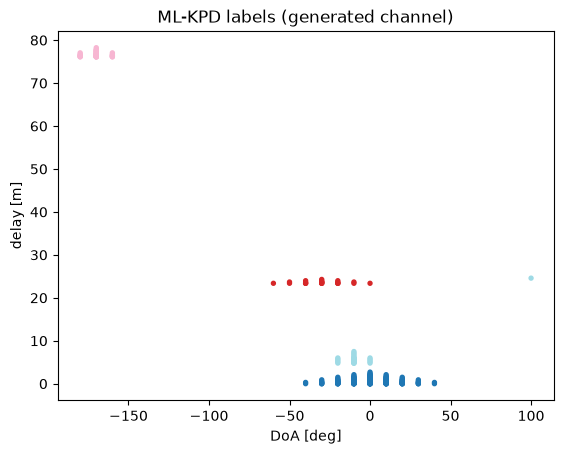

In [3]:
plt.scatter(np.rad2deg(taps.doa), taps.tau_m, c=res.labels, s=8, cmap='tab20')
plt.xlabel('DoA [deg]'); plt.ylabel('delay [m]'); plt.title('ML-KPD labels (generated channel)'); plt.show()